# Tutorial 2 — Averages and extremes

Notebook of the programming section of chapter 2 of R. Kühn, P. Vivo and F. Zamponi,
*Introduction to statistical physics for non-physicists* (Oxford University Press).

**How to run it.** Run all cells from top to bottom.
* *Locally (Jupyter):* run it from its folder; the data files are read from the folder if present.
* *On Google Colab:* [open it in Colab](https://colab.research.google.com/github/francescozamponi/statphys-tutorials/blob/main/Tutorial_2/Tutorial_2.ipynb)
  and run all cells; missing data files are downloaded automatically (from the book repository or from
  their original source), or you are asked to upload them.

The random number generator is seeded, so that the notebook reproduces the figures and numbers of the book.

In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import random
import scipy as sp
import scipy.stats
import os, sys, urllib.request

import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)

%matplotlib inline

np.random.seed(0)   # fix a seed for reproducibility

# Book repository, from which missing data files are downloaded
BOOK_REPO = 'https://raw.githubusercontent.com/francescozamponi/statphys-tutorials/main/'
FOLDER = 'Tutorial_2/'
IN_COLAB = 'google.colab' in sys.modules

def get_data(fname, sources=()):
    """Return fname if it is in the working folder; otherwise try to download it from the
    book repository and from `sources`; on Colab, as a last resort, ask to upload it."""
    if os.path.exists(fname):
        return fname
    for url in [BOOK_REPO + FOLDER + fname] + list(sources):
        try:
            urllib.request.urlretrieve(url, fname)
            print('downloaded', fname, 'from', url)
            return fname
        except Exception:
            pass
    if IN_COLAB:
        from google.colab import files
        print(f'Please upload {fname}')
        files.upload()
        if os.path.exists(fname):
            return fname
    raise FileNotFoundError(f'{fname} not found: download it into the folder of this notebook')

# Book formatting: every figure is saved at its printed size, so that all text prints at the
# same size in the book (bookfig.py; it does not change the plots). Without bookfig.py the
# figures are saved as they are.
sys.path[:0] = ['..', '../Figs_generator']
try:
    from bookfig import setup, save, HALF, SINGLE, FULL
except ImportError:                         # e.g. on Colab: fetch bookfig.py from the book repository
    try:
        urllib.request.urlretrieve(BOOK_REPO + 'bookfig.py', 'bookfig.py')
        from bookfig import setup, save, HALF, SINGLE, FULL
    except Exception:
        setup = None
if setup:
    setup()
else:
    HALF, SINGLE, FULL = 0.49, 0.7, 1.0
    def save(path, width, **kw):
        plt.savefig(path, bbox_inches='tight')

# EXPONENTIAL DISTRIBUTION

## Histograms. The variable $x$ is uniformly distributed, and the variable $y=-\log(1-x)$ is exponentially distributed.

In [2]:
M=10000000
x = np.random.uniform(size=M)
y = -np.log(1-x)

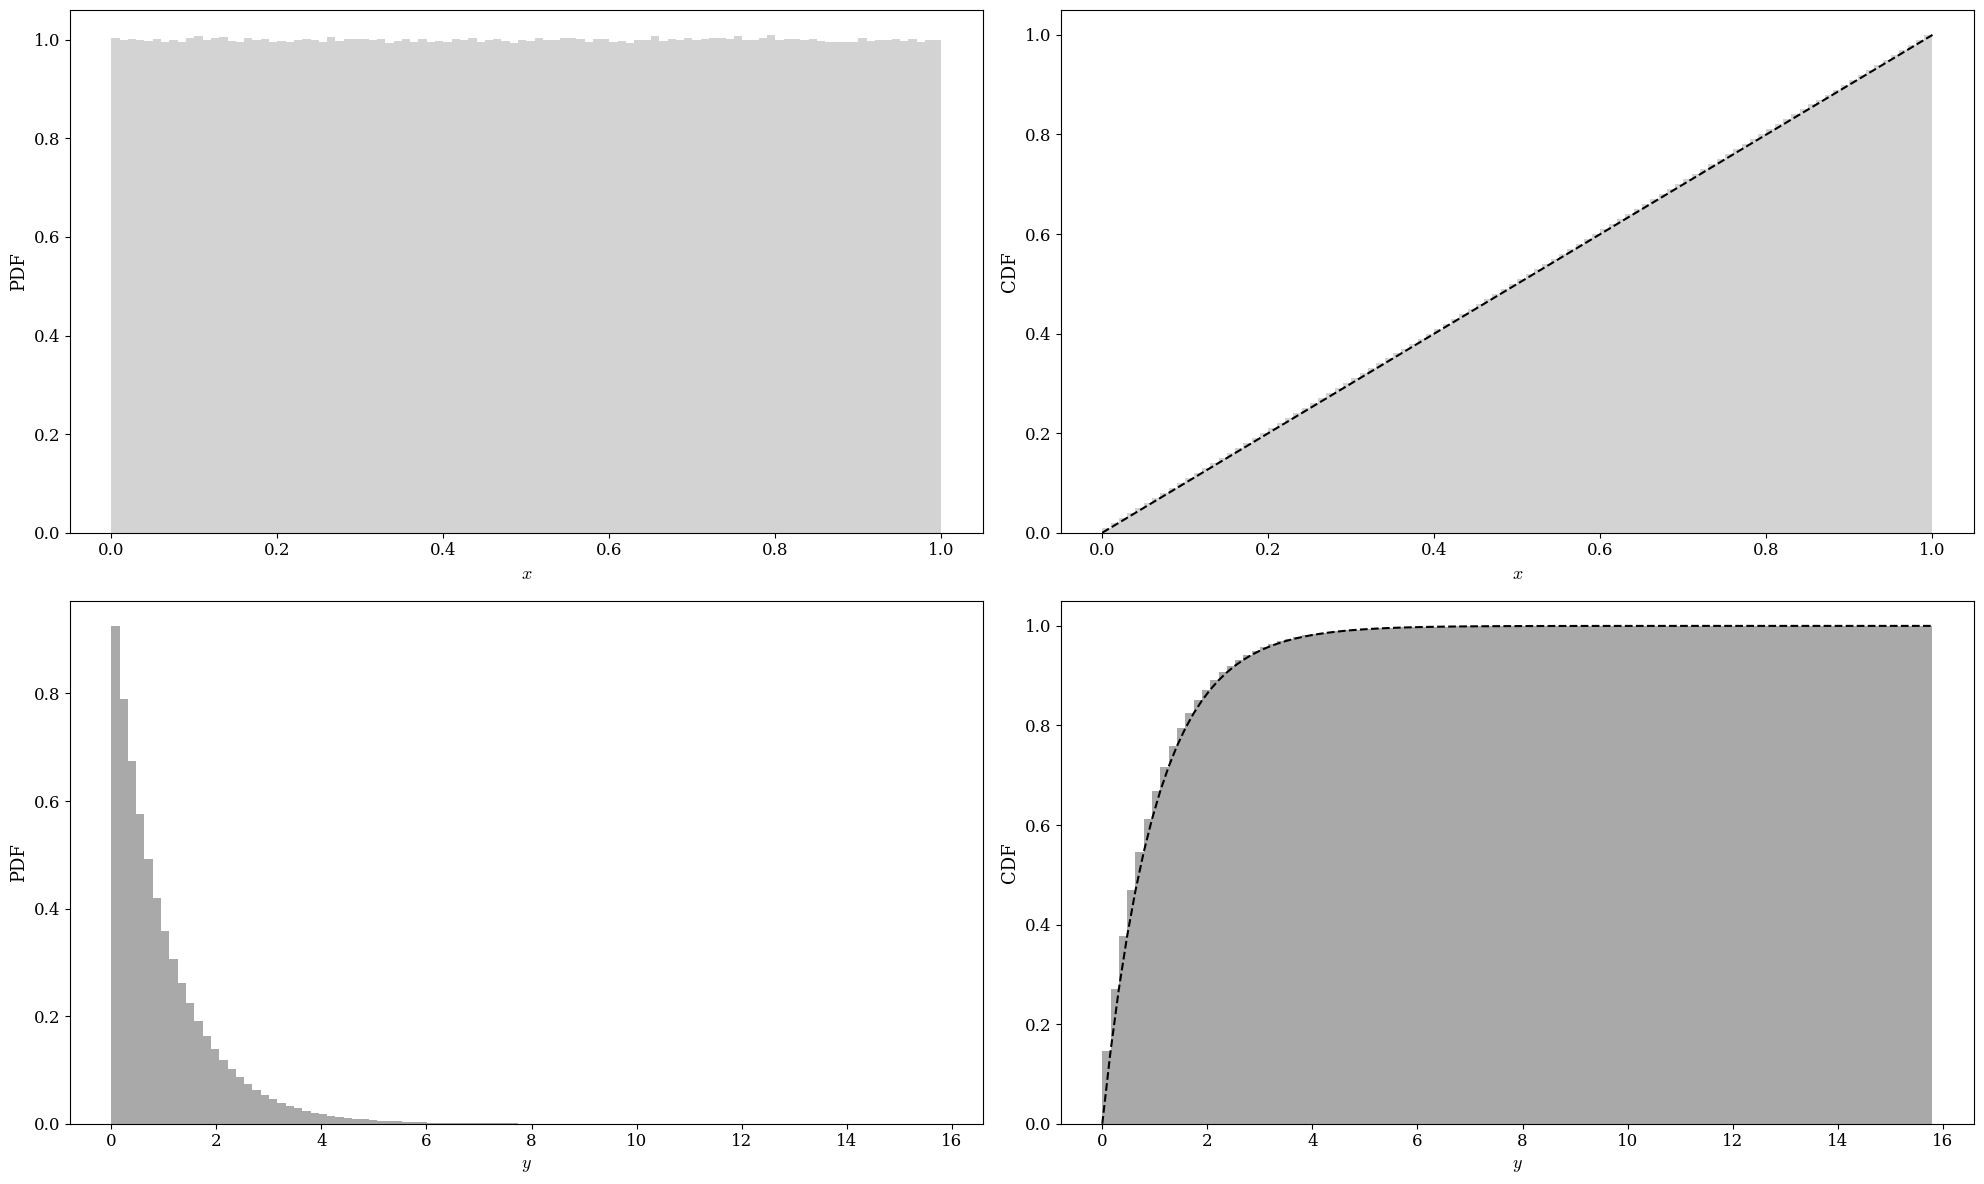

In [3]:
nbin=100

fig, ((ax0, ax2), (ax1, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(20,12))

n, bins, patches = ax0.hist(x, bins=nbin, facecolor='lightgrey',density=True);
ax0.set_xlabel('$x$')
ax0.set_ylabel('PDF')

n, bins, patches = ax1.hist(y, bins=nbin, facecolor='darkgrey',density=True);
ax1.set_xlabel('$y$')
ax1.set_ylabel('PDF')

n, bins, patches = ax2.hist(x, bins=nbin, facecolor='lightgrey',density=True,cumulative=True);
ax2.set_xlabel('$x$')
ax2.set_ylabel('CDF')
ax2.plot(bins, bins, '--', color ='black')

n, bins, patches = ax3.hist(y, bins=nbin, facecolor='darkgrey',density=True,cumulative=True);
ax3.set_xlabel('$y$')
ax3.set_ylabel('CDF')
ax3.plot(bins, 1-np.exp(-bins), '--', color ='black')

plt.tight_layout()
plt.show()

## Extract at random $k$ sets of $n$ values of $y$. We study the maximum and check that its distribution is given by the Gumbel law.

In [4]:
n=200
k=int(M/n)
random_set=np.random.choice(y, (k,n))
max_set=np.max(random_set, axis=1)
xmean=np.mean(random_set, axis=1)

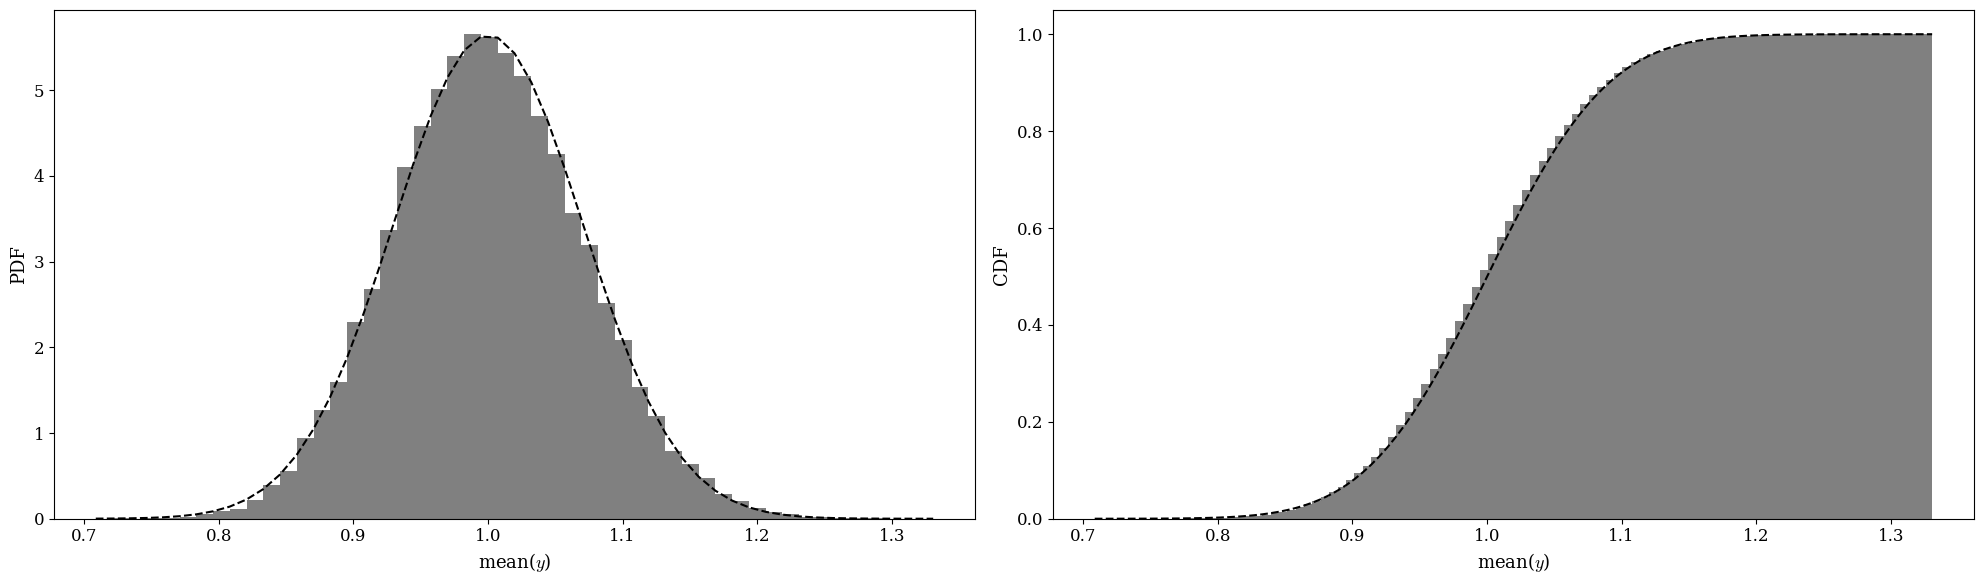

In [5]:
fig, ((ax1, ax3)) = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

n, bins, patches = ax1.hist(xmean, bins=50, facecolor='grey',density=True);
ax1.set_xlabel('mean($y$)')
ax1.set_ylabel('PDF')
ax1.plot(bins, sp.stats.norm.pdf(bins, loc=np.mean(xmean), scale=np.std(xmean)), '--', color ='black')

n, bins, patches = ax3.hist(xmean, bins=100, facecolor='grey',density=True,cumulative=True);
ax3.set_xlabel('mean($y$)')
ax3.set_ylabel('CDF')
ax3.plot(bins, sp.stats.norm.cdf(bins, loc=np.mean(xmean), scale=np.std(xmean)), '--', color ='black')

plt.tight_layout()
plt.show()

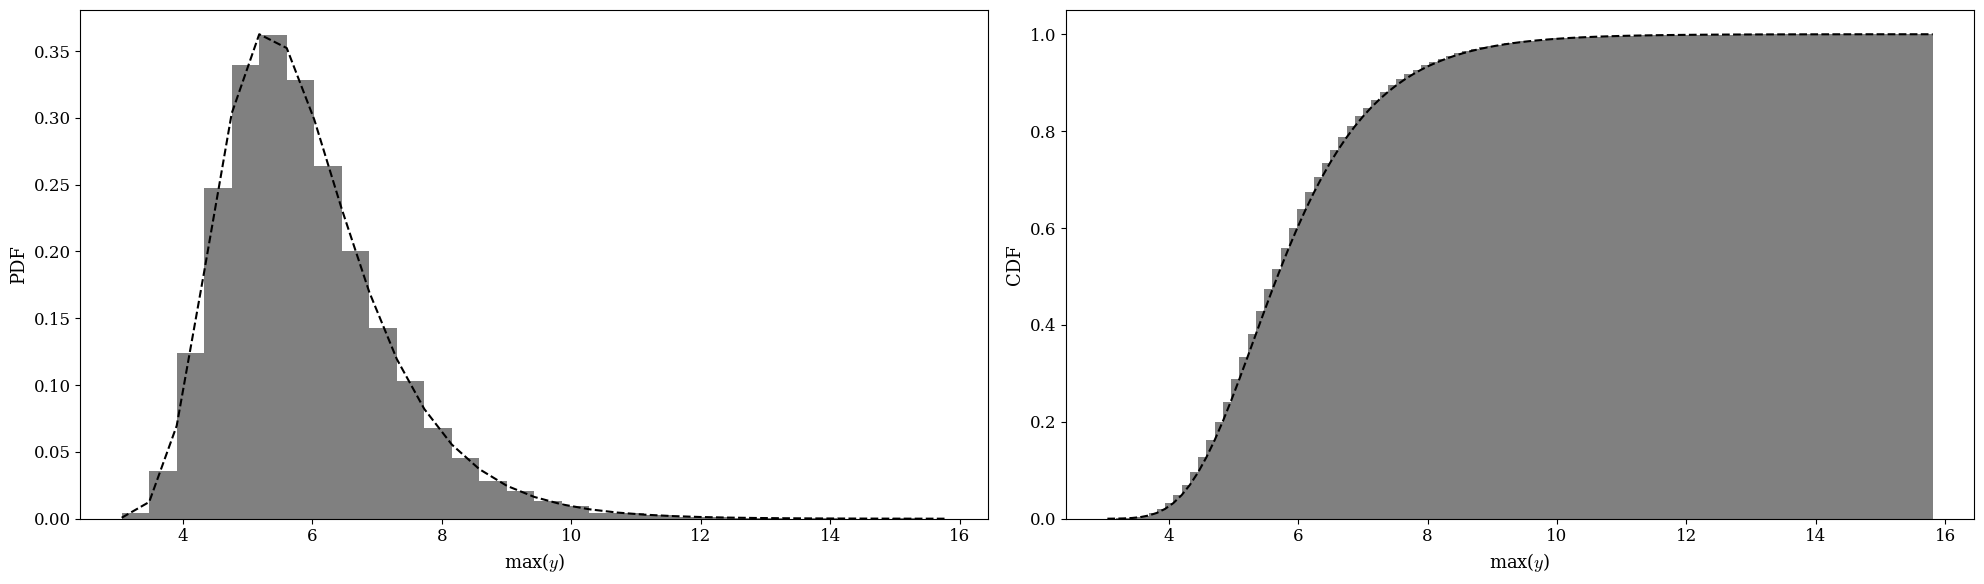

In [6]:
fig, ((ax1, ax3)) = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

n, bins, patches = ax1.hist(max_set, bins=30, facecolor='grey',density=True);
ax1.set_xlabel('max($y$)')
ax1.set_ylabel('PDF')
ax1.plot(bins, sp.stats.gumbel_r.pdf(bins, loc=np.mean(max_set)-0.577*np.sqrt(6.)/3.14*np.std(max_set), scale=np.sqrt(6.)/3.14*np.std(max_set)), '--', color ='black')

n, bins, patches = ax3.hist(max_set, bins=100, facecolor='grey',density=True,cumulative=True);
ax3.set_xlabel('max($y$)')
ax3.set_ylabel('CDF')
ax3.plot(bins, sp.stats.gumbel_r.cdf(bins, loc=np.mean(max_set)-0.577*np.sqrt(6.)/3.14*np.std(max_set), scale=np.sqrt(6.)/3.14*np.std(max_set)), '--', color ='black')

plt.tight_layout()
plt.show()

# REAL DATA

## Importing the data

### T-cell receptor repertoires

TCR$\beta$ repertoires of four healthy donors, from Emerson *et al.*, Nat. Genet. **49**, 659 (2017);
subset distributed with [MetaTCR](https://github.com/deepomicslab/MetaTCR), folder
`data/demo_data/Emerson2017_demo`. The function below rebuilds `tcr_clone_sizes.csv` from the original
repertoires: it extracts the receptor sequence (`cdr3`), the V gene and the clone size (`count`),
concatenates the four donors and discards the clones observed only once (39,749 clones remain).
It is run only if the CSV file is not available.

In [7]:
def make_tcr_csv(fname='tcr_clone_sizes.csv'):
    base = 'https://raw.githubusercontent.com/deepomicslab/MetaTCR/v2.0.0/data/demo_data/Emerson2017_demo/'
    donors = ['CMVneg/HIP01161', 'CMVneg/HIP01162', 'CMVpos/HIP01850', 'CMVpos/HIP01856']
    L = []
    for f in donors:
        d = pd.read_csv(base + f + '.tsv', sep='\t')
        L.append(pd.DataFrame({'donor': f.split('/')[1],
                               'cdr3': d['aminoAcid'],
                               'v_gene': d['vMaxResolved'],
                               'count': d['count (templates/reads)']}))
    D = pd.concat(L)
    D = D[D['count'] >= 2]
    D.to_csv(fname, index=False)
    print(len(D), 'clones written to', fname)   # 39749

try:
    get_data('tcr_clone_sizes.csv')
except FileNotFoundError:
    make_tcr_csv()
clone_data = pd.read_csv('tcr_clone_sizes.csv')

### Heights and weights

25,000 heights and weights of 18-year-old men (SOCR data, Dinov 2008), distributed on
[Kaggle](https://www.kaggle.com/datasets/burnoutminer/heights-and-weights-dataset/).
If `SOCR-HeightWeight.csv` is not available, it is downloaded with `kagglehub`
(pre-installed on Colab; elsewhere `pip install kagglehub`), or you can download it by hand.

In [8]:
try:
    get_data('SOCR-HeightWeight.csv')
except FileNotFoundError:
    import kagglehub, glob, shutil
    folder = kagglehub.dataset_download('burnoutminer/heights-and-weights-dataset')
    shutil.copy(glob.glob(os.path.join(folder, '*.csv'))[0], 'SOCR-HeightWeight.csv')
weight_data = pd.read_csv('SOCR-HeightWeight.csv')

In [9]:
clone_data

,donor,cdr3,v_gene,count
0,HIP01161,CASSQDLYGGSSYEQYF,TCRBV04-02*01,541
1,HIP01161,CASSYGTSTDTQYF,TCRBV06,468
2,HIP01161,CASSLWAKPYEQYF,TCRBV27-01*01,264
3,HIP01161,CASRDTLSYEQYF,TCRBV07-09,258
4,HIP01161,CATIQGWGETQYF,TCRBV28-01*01,177
...,...,...,...,...
39744,HIP01856,CASSPGGSLDGYTF,TCRBV11-02*02,2
39745,HIP01856,CASSPGGTDTQYF,TCRBV04-01*01,2
39746,HIP01856,CASSPGGTEAFF,TCRBV11-01*01,2
39747,HIP01856,CASSPGGTETQYF,TCRBV19-01,2


In [10]:
weight_data

,Index,Height(Inches),Weight(Pounds)
0,1,65.78331,112.9925
1,2,71.51521,136.4873
2,3,69.39874,153.0269
3,4,68.21660,142.3354
4,5,67.78781,144.2971
...,...,...,...
24995,24996,69.50215,118.0312
24996,24997,64.54826,120.1932
24997,24998,64.69855,118.2655
24998,24999,67.52918,132.2682


In [11]:
clones = np.array(clone_data.loc[:,"count"]).astype(float)
Nclones=len(clones)
print(Nclones,np.mean(clones),np.std(clones))

39749 4.530478754182496 40.00057118167163


In [12]:
weights = np.array(weight_data.loc[:,"Weight(Pounds)"])
Nweights=len(weights)
print(Nweights,np.mean(weights),np.std(weights))

25000 127.07942116080001 11.66066434332078


## Histograms, means and variances

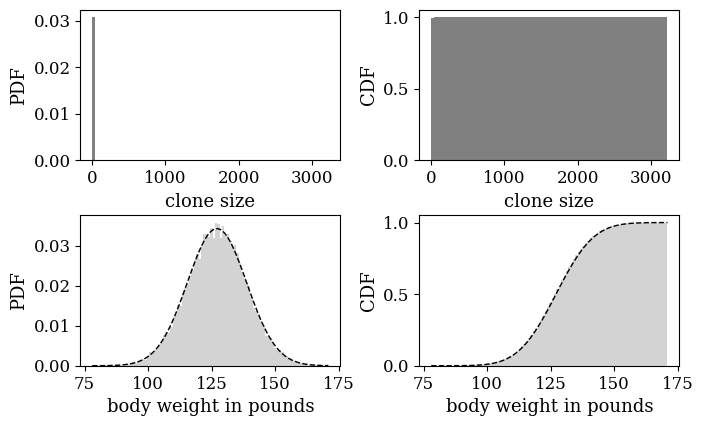

In [13]:
fig, ((ax0, ax2), (ax1, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(20,12))

n, bins, patches = ax0.hist(clones, bins=100, facecolor='grey',density=True);
ax0.set_xlabel('clone size')
ax0.set_ylabel('PDF')

n, bins, patches = ax1.hist(weights, bins=100, facecolor='lightgrey', density=True);
ax1.set_xlabel('body weight in pounds')
ax1.set_ylabel('PDF')
ax1.plot(bins, sp.stats.norm.pdf(bins, loc=np.mean(weights), scale=np.std(weights)), '--', color ='black', linewidth=3)

n, bins, patches = ax2.hist(clones, bins=100, facecolor='grey',density=True,cumulative=True);
ax2.set_xlabel('clone size')
ax2.set_ylabel('CDF')

n, bins, patches = ax3.hist(weights, bins=100, facecolor='lightgrey',density=True,cumulative=True);
ax3.set_xlabel('body weight in pounds')
ax3.set_ylabel('CDF')
ax3.plot(bins, sp.stats.norm.cdf(bins, loc=np.mean(weights), scale=np.std(weights)), '--', color ='black', linewidth=3)

plt.tight_layout()
save("histograms.pdf", FULL)

plt.show()

## Pareto tail $P(C>x) = q\,(x/x_{\min})^{-\alpha}$ for $x\geq x_{\min}$, where $q$ is the fraction of clones larger than $x_{\min}$

q=  0.01290598505622783


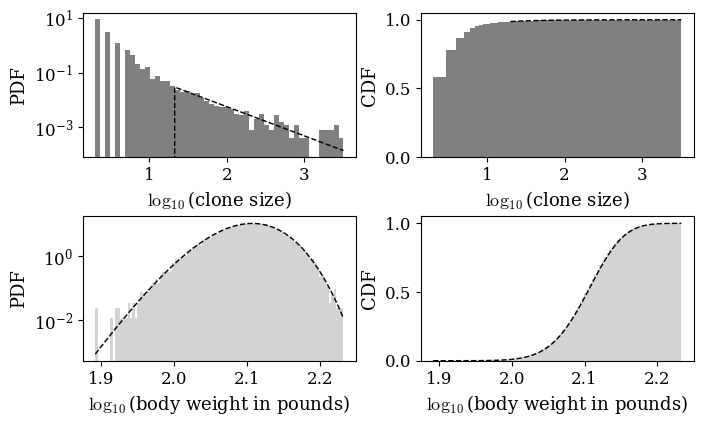

In [14]:
alpha=1.07
xmin=20
q=np.mean(clones>=xmin)
print("q= ",q)

def Pareto(x):
    if x>np.log10(xmin):
        return np.log(10)*q*alpha*np.power(10,alpha*(np.log10(xmin)-x))
    else:
        return 0

fig, ((ax0, ax2), (ax1, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(20,12))

n, bins, patches = ax0.hist(np.log10(clones), bins=50, facecolor='grey', density=True);
ax0.set_yscale('log')
ax0.set_xlabel(r'$\log_{10}$(clone size)')
ax0.set_ylabel('PDF')
ax0.plot(bins, [Pareto(x) for x in bins], '--', color ='black', linewidth=3)

n, bins, patches = ax1.hist(np.log10(weights), bins=100, facecolor='lightgrey', density=True);
ax1.set_yscale('log')
ax1.set_xlabel(r'$\log_{10}$(body weight in pounds)')
ax1.set_ylabel('PDF')
ax1.plot(bins, np.log(10)*np.power(10,bins)*sp.stats.norm.pdf(np.power(10,bins), loc=np.mean(weights), scale=np.std(weights)), '--', color ='black', linewidth=3)

n, bins, patches = ax2.hist(np.log10(clones), bins=500, facecolor='grey', density=True, cumulative=True);
ax2.set_xlabel(r'$\log_{10}$(clone size)')
ax2.set_ylabel('CDF')
ax2.plot(bins, np.where(bins>=np.log10(xmin), 1.-q*np.power(10,alpha*(np.log10(xmin)-bins)), np.nan), '--', color ='black', linewidth=3)

n, bins, patches = ax3.hist(np.log10(weights), bins=100, facecolor='lightgrey', density=True, cumulative=True);
ax3.set_xlabel(r'$\log_{10}$(body weight in pounds)')
ax3.set_ylabel('CDF')
ax3.plot(bins, sp.stats.norm.cdf(np.power(10,bins), loc=np.mean(weights), scale=np.std(weights)), '--', color ='black', linewidth=3)

plt.tight_layout()
save("loghistograms.pdf", FULL)

plt.show()

127.2229027927928 12.00381822367577


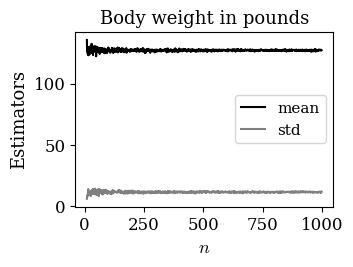

In [15]:
Ndata=Nweights
Nmin=10
Nmax=1000
ndata = np.zeros(Nmax-Nmin)
mu = np.zeros(Nmax-Nmin)
sigma = np.zeros(Nmax-Nmin)
for n in range(Nmin,Nmax):
   ndata[n-Nmin] = n
   mu[n-Nmin] = np.mean(np.random.choice(weights, n))
   sigma[n-Nmin] = np.std(np.random.choice(weights, n))
print(mu[-1],sigma[-1])
plt.plot(ndata,mu,label='mean',color='black')
plt.plot(ndata,sigma,label='std',color='grey')
plt.xlabel('$n$')
plt.ylabel('Estimators')
plt.title('Body weight in pounds')
plt.legend()
plt.tight_layout()
save("Wmeanstd.pdf", HALF)
plt.show()

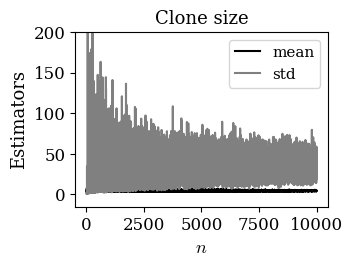

In [16]:
Ndata=Nclones
Nmin=10
Nmax=10000
ndata = np.zeros(Nmax-Nmin)
mu = np.zeros(Nmax-Nmin)
sigma = np.zeros(Nmax-Nmin)
for n in range(Nmin,Nmax):
   ndata[n-Nmin] = n
   mu[n-Nmin] = np.mean(np.random.choice(clones, n))
   sigma[n-Nmin] = np.std(np.random.choice(clones, n))
plt.plot(ndata,mu,label='mean',color='black')
plt.plot(ndata,sigma,label='std',color='grey')
plt.xlabel('$n$')
plt.ylabel('Estimators')
plt.ylim(top=200)
plt.title('Clone size')
plt.legend()
plt.tight_layout()
save("Cmeanstd.pdf", HALF)
plt.show()

## Extract at random k sets of n values and study the maximum and the partial sums

In [17]:
n=200
random_weights=np.random.choice(weights, (int(len(weights)/n),n))
random_clones=np.random.choice(clones, (int(len(clones)/n),n))
av_weights=np.mean(random_weights, axis=1)
av_clones=np.mean(random_clones, axis=1)
max_weights=np.max(random_weights, axis=1)
max_clones=np.max(random_clones, axis=1)
# Frechet scale predicted from the Pareto tail
an=xmin*np.power(n*q,1/alpha)
print(an)
# Levy-stable law for the mean: alpha and beta=1 from the tail, scale predicted from the tail,
# location fixed by matching the median of the data
sn=np.power(q*np.power(xmin,alpha)*np.pi/(2*math.gamma(alpha)*np.sin(np.pi*alpha/2)),1/alpha)*np.power(n,1/alpha-1)
ln=np.median(av_clones)-sp.stats.levy_stable.median(alpha,1,loc=0,scale=sn)
print(sn,ln)

48.518747199260595
0.3849860810433108 6.839086144095481


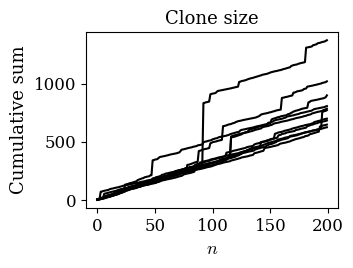

In [18]:
for i in range(10):
    plt.plot(random_clones[i,:].cumsum(),color='black')
plt.xlabel('$n$')
plt.ylabel('Cumulative sum')
plt.title('Clone size')
plt.tight_layout()
save("clonesum.pdf", HALF)
plt.show()

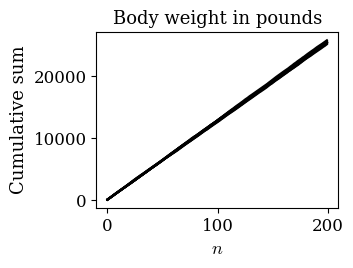

In [19]:
for i in range(10):
    plt.plot(random_weights[i,:].cumsum(),color='black')
plt.xlabel('$n$')
plt.ylabel('Cumulative sum')
plt.title('Body weight in pounds')
plt.tight_layout()
save("weightsum.pdf", HALF)
plt.show()

In [20]:
# fraction of the total held by the largest element of each group
print(np.mean(max_weights/np.sum(random_weights,axis=1)), np.mean(max_clones/np.sum(random_clones,axis=1)))

0.006256375876296029 0.15841018074142396


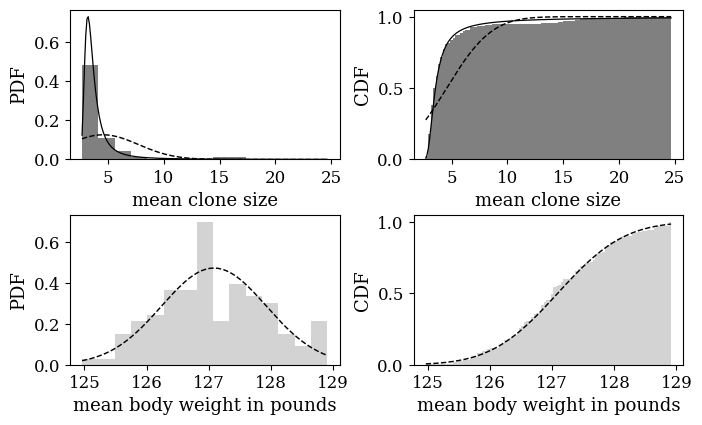

In [21]:
fig, ((ax0, ax2), (ax1, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(20,12))

n, bins, patches = ax0.hist(av_clones, bins=15, facecolor='grey', density=True);
ax0.set_xlabel('mean clone size')
ax0.set_ylabel('PDF')
xx=np.linspace(bins[0],bins[-1],200)
ax0.plot(xx, sp.stats.norm.pdf(xx, loc=np.mean(av_clones), scale=np.std(av_clones)), '--', color ='black', linewidth=3)
ax0.plot(xx, sp.stats.levy_stable.pdf(xx, alpha, 1, loc=ln, scale=sn), '-', color ='black', linewidth=2)

n, bins, patches = ax1.hist(av_weights, bins=15, facecolor='lightgrey', density=True);
ax1.set_xlabel('mean body weight in pounds')
ax1.set_ylabel('PDF')
xx=np.linspace(bins[0],bins[-1],200)
ax1.plot(xx, sp.stats.norm.pdf(xx, loc=np.mean(av_weights), scale=np.std(av_weights)), '--', color ='black', linewidth=3)

n, bins, patches = ax2.hist(av_clones, bins=100, facecolor='grey',density=True,cumulative=True);
ax2.set_xlabel('mean clone size')
ax2.set_ylabel('CDF')
xx=np.linspace(bins[0],bins[-1],200)
ax2.plot(xx, sp.stats.norm.cdf(xx, loc=np.mean(av_clones), scale=np.std(av_clones)), '--', color ='black', linewidth=3)
ax2.plot(xx, sp.stats.levy_stable.cdf(xx, alpha, 1, loc=ln, scale=sn), '-', color ='black', linewidth=2)

n, bins, patches = ax3.hist(av_weights, bins=100, facecolor='lightgrey',density=True,cumulative=True);
ax3.set_xlabel('mean body weight in pounds')
ax3.set_ylabel('CDF')
ax3.plot(bins, sp.stats.norm.cdf(bins, loc=np.mean(av_weights), scale=np.std(av_weights)), '--', color ='black', linewidth=3)

plt.tight_layout()
save("meanhistograms.pdf", FULL)

plt.show()

## Maximum: Fréchet law for clone sizes, with shape $\alpha$ and scale $a_n = x_{\min}(nq)^{1/\alpha}$ predicted from the tail (no fit); Gumbel law for weights

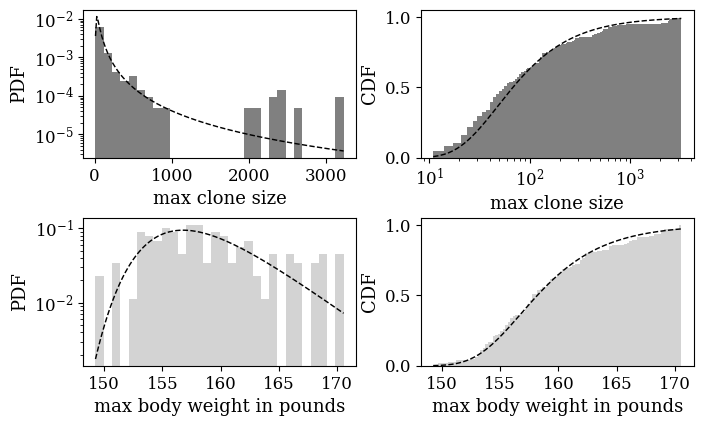

In [22]:
fig, ((ax0, ax2), (ax1, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(20,12))

n, bins, patches = ax0.hist(max_clones, bins=30, facecolor='grey', density=True);
ax0.set_yscale('log')
ax0.set_xlabel('max clone size')
ax0.set_ylabel('PDF')
xx=np.linspace(bins[0],bins[-1],200)
ax0.plot(xx, sp.stats.invweibull.pdf(xx, alpha, scale=an), '--', color ='black', linewidth=3)

n, bins, patches = ax1.hist(max_weights, bins=30, facecolor='lightgrey', density=True);
ax1.set_yscale('log')
ax1.set_xlabel('max body weight in pounds')
ax1.set_ylabel('PDF')
xx=np.linspace(bins[0],bins[-1],200)
ax1.plot(xx, sp.stats.gumbel_r.pdf(xx, loc=np.mean(max_weights)-0.577*np.sqrt(6.)/3.14*np.std(max_weights), scale=np.sqrt(6.)/3.14*np.std(max_weights)), '--', color ='black', linewidth=3)

n, bins, patches = ax2.hist(max_clones, bins=1000, facecolor='grey',density=True,cumulative=True);
ax2.set_xscale('log')
ax2.set_xlabel('max clone size')
ax2.set_ylabel('CDF')
xx=np.linspace(bins[0],bins[-1],2000)
ax2.plot(xx, sp.stats.invweibull.cdf(xx, alpha, scale=an), '--', color ='black', linewidth=3)

n, bins, patches = ax3.hist(max_weights, bins=100, facecolor='lightgrey',density=True,cumulative=True);
ax3.set_xlabel('max body weight in pounds')
ax3.set_ylabel('CDF')
xx=np.linspace(bins[0],bins[-1],200)
ax3.plot(xx, sp.stats.gumbel_r.cdf(xx, loc=np.mean(max_weights)-0.577*np.sqrt(6.)/3.14*np.std(max_weights), scale=np.sqrt(6.)/3.14*np.std(max_weights)), '--', color ='black', linewidth=3)

plt.tight_layout()
save("maxhistograms.pdf", FULL)

plt.show()

# APPENDIX: CITY POPULATIONS

An alternative to the T-cell repertoires (footnote in the problem): the populations of the cities of the
world, from the free *basic* database of [simplemaps](https://simplemaps.com/data/world-cities)
(CC BY 4.0). The file `worldcities.csv` used in the book is included in the book repository (44,691
cities; discarding those whose population is zero or NaN, 44,380 remain). The populations have a
Pareto tail $P(X>x) = q\,(x/x_{\min})^{-\alpha}$ with $\alpha\approx 0.88<1$, for which the mean would be
infinite. In the data the tail is cut off by the largest cities (Tokyo, with $3.8\times 10^7$
inhabitants, is far below the largest value that a pure Pareto tail would produce among 44,380 cities),
which matters for the averages and the maxima below. The analysis parallels the one of the clone sizes, with the body weights for comparison.

In [23]:
city_data = pd.read_csv(get_data('worldcities.csv'))
print(len(city_data), 'cities')
pops = np.array(city_data.population, dtype=float)
pops = pops[np.isfinite(pops) & (pops > 0)]
Npops = len(pops)
print(Npops, 'cities with a population', np.mean(pops), np.std(pops))

44691 cities
44380 cities with a population 114384.2347453808 714877.5581500175


## Histograms, with the Pareto tail of the populations

q =  0.8700991437584498


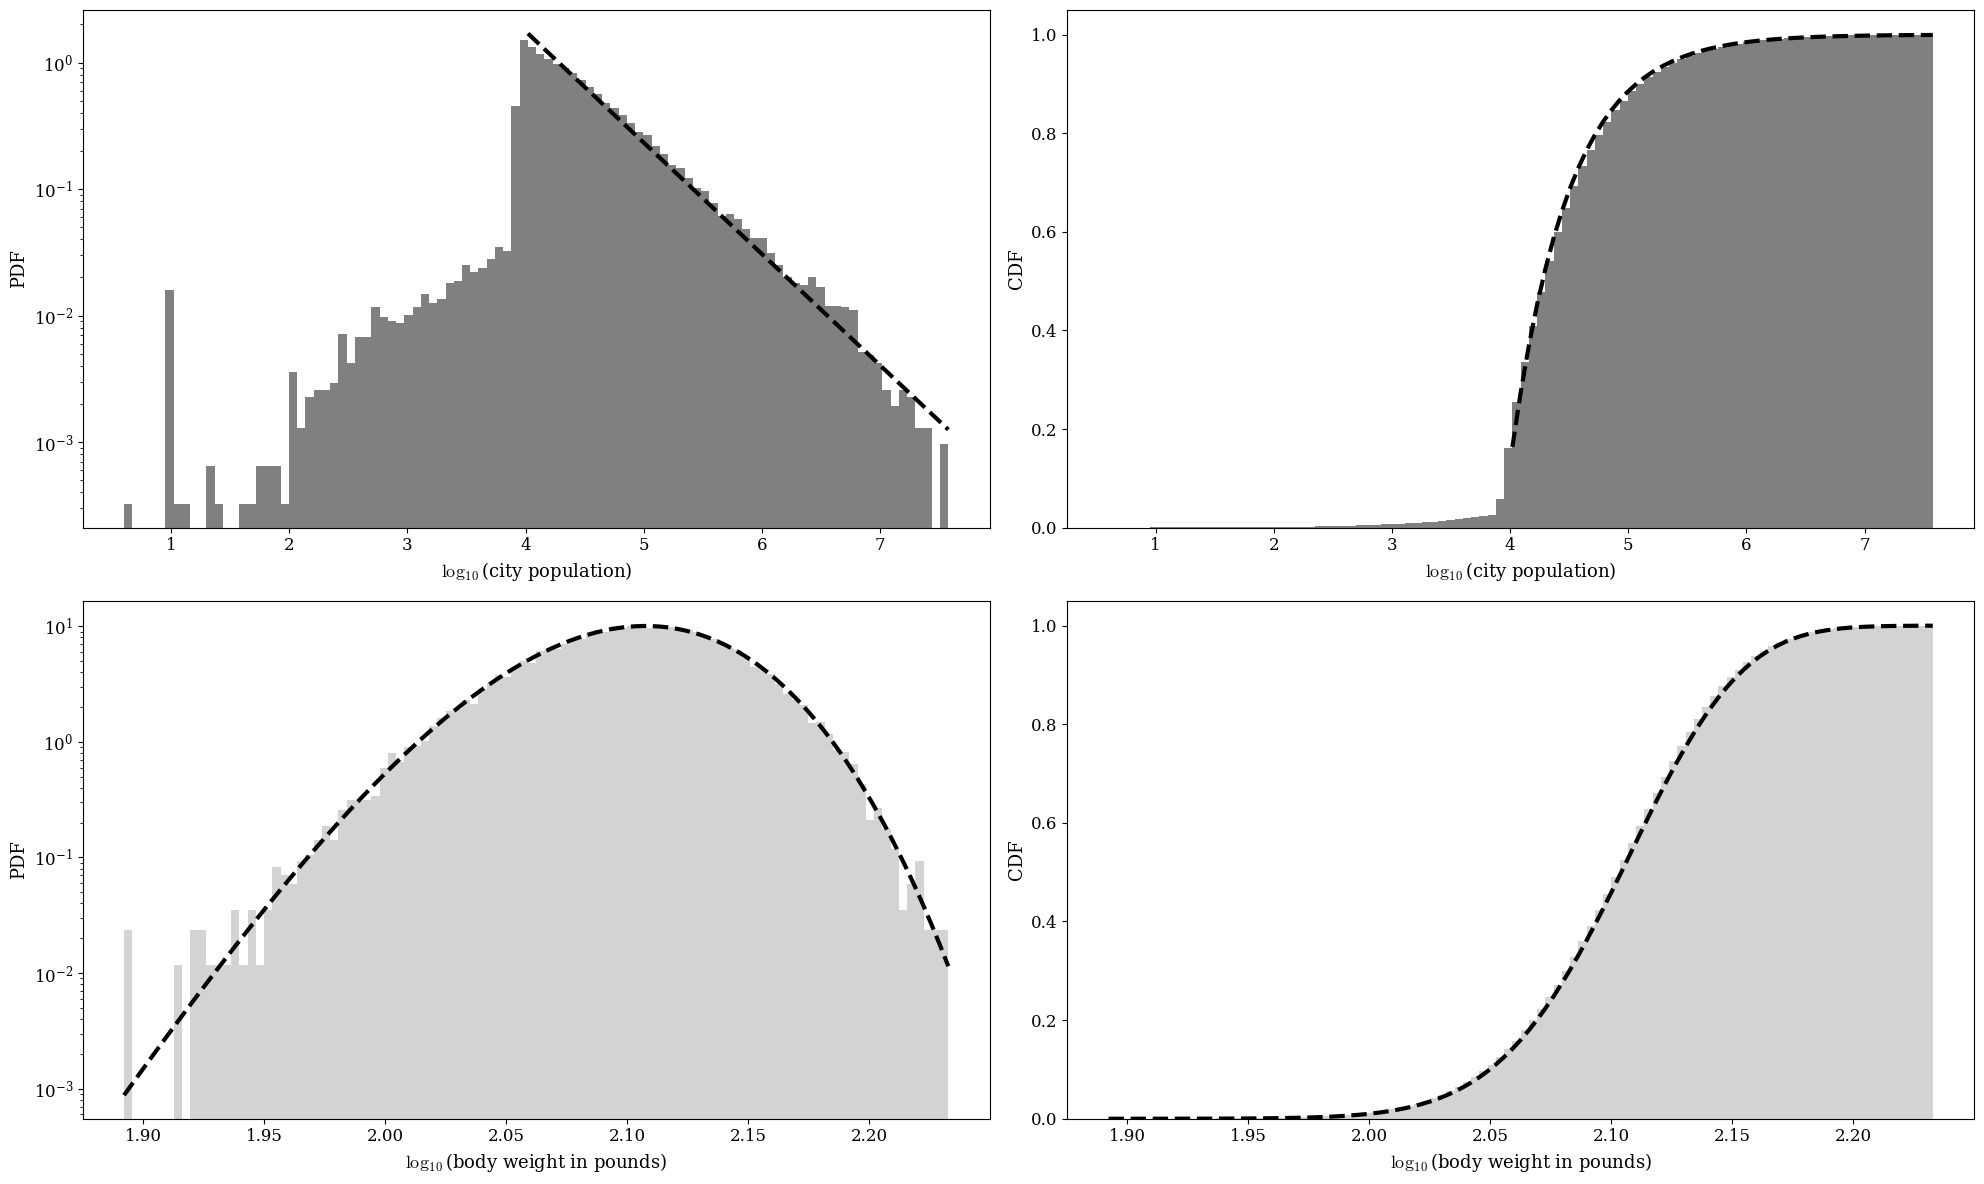

In [24]:
alpha_c = 0.88
xmin_c = 1e4
q_c = np.mean(pops >= xmin_c)
print('q = ', q_c)

fig, ((ax0, ax2), (ax1, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(20,12))

n, bins, patches = ax0.hist(np.log10(pops), bins=100, facecolor='grey', density=True);
ax0.set_yscale('log')
ax0.set_xlabel(r'$\log_{10}$(city population)')
ax0.set_ylabel('PDF')
xx = bins[bins >= np.log10(xmin_c)]
ax0.plot(xx, np.log(10)*q_c*alpha_c*np.power(10, alpha_c*(np.log10(xmin_c)-xx)), '--', color='black', linewidth=3)

n, bins, patches = ax1.hist(np.log10(weights), bins=100, facecolor='lightgrey', density=True);
ax1.set_yscale('log')
ax1.set_xlabel(r'$\log_{10}$(body weight in pounds)')
ax1.set_ylabel('PDF')
ax1.plot(bins, np.log(10)*np.power(10,bins)*sp.stats.norm.pdf(np.power(10,bins), loc=np.mean(weights), scale=np.std(weights)), '--', color='black', linewidth=3)

n, bins, patches = ax2.hist(np.log10(pops), bins=100, facecolor='grey', density=True, cumulative=True);
ax2.set_xlabel(r'$\log_{10}$(city population)')
ax2.set_ylabel('CDF')
ax2.plot(bins, np.where(bins >= np.log10(xmin_c), 1 - q_c*np.power(10, alpha_c*(np.log10(xmin_c)-bins)), np.nan), '--', color='black', linewidth=3)

n, bins, patches = ax3.hist(np.log10(weights), bins=100, facecolor='lightgrey', density=True, cumulative=True);
ax3.set_xlabel(r'$\log_{10}$(body weight in pounds)')
ax3.set_ylabel('CDF')
ax3.plot(bins, sp.stats.norm.cdf(np.power(10,bins), loc=np.mean(weights), scale=np.std(weights)), '--', color='black', linewidth=3)

plt.tight_layout()
plt.show()

## Empirical mean and standard deviation of $n$ cities. For a pure Pareto tail with $\alpha<1$ they would not converge; here they jump each time a very large city is drawn, and settle only because the dataset is finite.

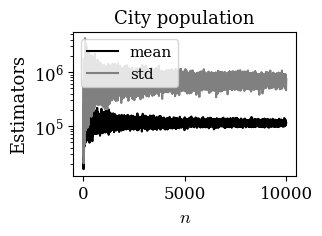

In [25]:
Nmin=10
Nmax=10000
ndata = np.arange(Nmin, Nmax)
mu = np.array([np.mean(np.random.choice(pops, n)) for n in ndata])
sigma = np.array([np.std(np.random.choice(pops, n)) for n in ndata])
plt.plot(ndata, mu, label='mean', color='black')
plt.plot(ndata, sigma, label='std', color='grey')
plt.xlabel('$n$')
plt.ylabel('Estimators')
plt.yscale('log')
plt.title('City population')
plt.legend()
plt.tight_layout()
plt.show()

## Sets of $n$ cities: cumulative sums, mean and maximum

3516696.8169847596 27314.1231261005 -59238.11630838507
0.24757980054391213


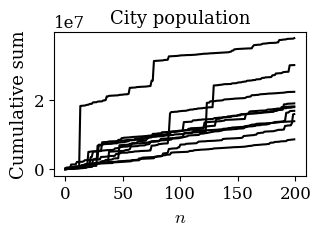

In [26]:
n=200
random_pops = np.random.choice(pops, (int(len(pops)/n), n))
av_pops = np.mean(random_pops, axis=1)
max_pops = np.max(random_pops, axis=1)
# Frechet scale predicted from the Pareto tail (as for the clone sizes)
an_c = xmin_c*np.power(n*q_c, 1/alpha_c)
# Levy-stable law for the mean (alpha < 1): scale predicted from the tail, location from the median
sn_c = np.power(q_c*np.power(xmin_c,alpha_c)*np.pi/(2*math.gamma(alpha_c)*np.sin(np.pi*alpha_c/2)), 1/alpha_c)*np.power(n, 1/alpha_c-1)
ln_c = np.median(av_pops) - sp.stats.levy_stable.median(alpha_c, 1, loc=0, scale=sn_c)
print(an_c, sn_c, ln_c)
# fraction of the total held by the largest city of each set
print(np.mean(max_pops/np.sum(random_pops, axis=1)))

for i in range(10):
    plt.plot(random_pops[i,:].cumsum(), color='black')
plt.xlabel('$n$')
plt.ylabel('Cumulative sum')
plt.title('City population')
plt.tight_layout()
plt.show()

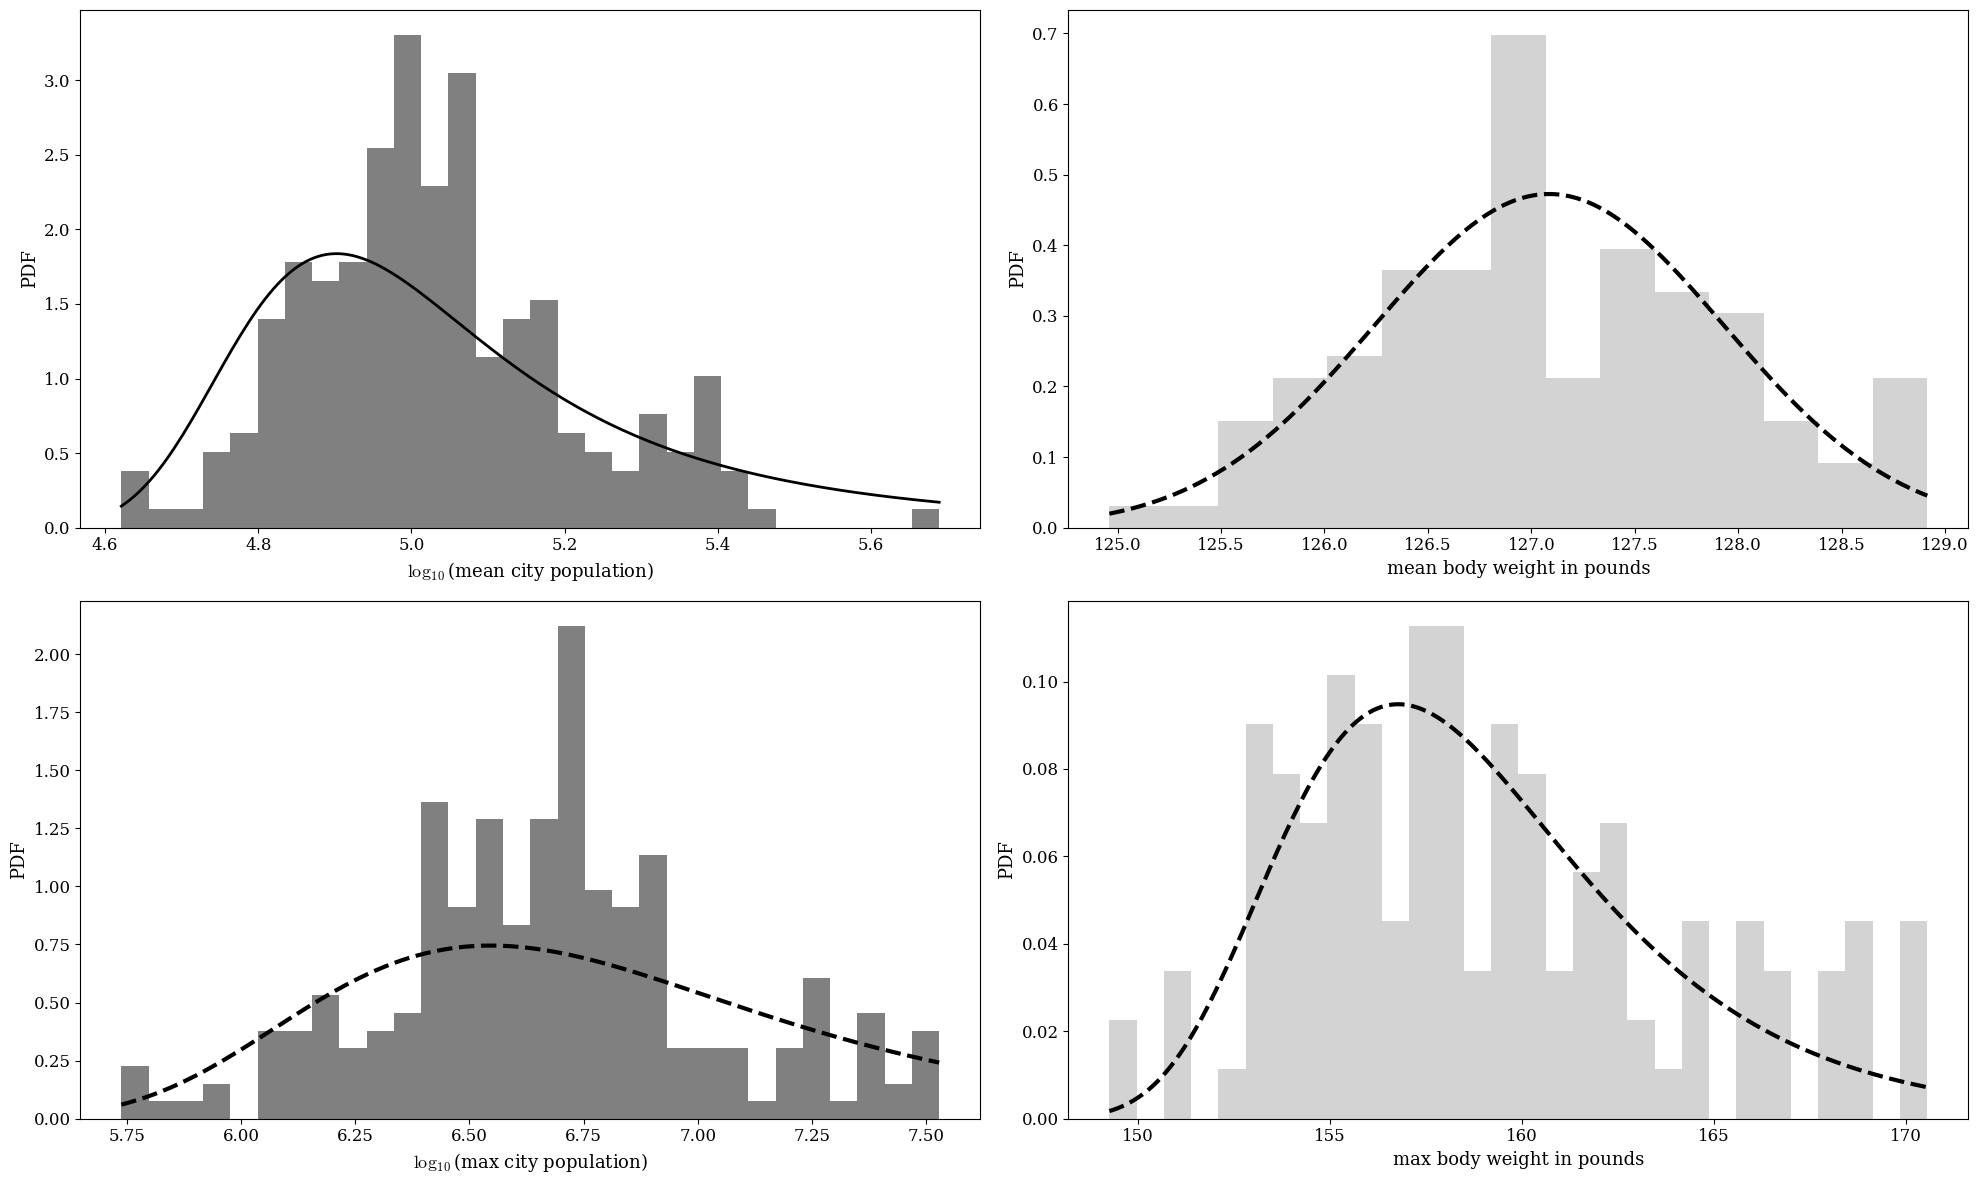

In [27]:
fig, ((ax0, ax2), (ax1, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(20,12))

n_, bins, patches = ax0.hist(np.log10(av_pops), bins=30, facecolor='grey', density=True);
ax0.set_xlabel(r'$\log_{10}$(mean city population)')
ax0.set_ylabel('PDF')
xx = np.linspace(bins[0], bins[-1], 200)
ax0.plot(xx, np.log(10)*np.power(10,xx)*sp.stats.levy_stable.pdf(np.power(10,xx), alpha_c, 1, loc=ln_c, scale=sn_c), '-', color='black', linewidth=2)

n_, bins, patches = ax1.hist(np.log10(max_pops), bins=30, facecolor='grey', density=True);
ax1.set_xlabel(r'$\log_{10}$(max city population)')
ax1.set_ylabel('PDF')
xx = np.linspace(bins[0], bins[-1], 200)
# Frechet law predicted from the Pareto tail; it overestimates the largest maxima,
# because the tail of the data is cut off by the largest cities
ax1.plot(xx, np.log(10)*np.power(10,xx)*sp.stats.invweibull.pdf(np.power(10,xx), alpha_c, scale=an_c), '--', color='black', linewidth=3)

n_, bins, patches = ax2.hist(av_weights, bins=15, facecolor='lightgrey', density=True);
ax2.set_xlabel('mean body weight in pounds')
ax2.set_ylabel('PDF')
xx = np.linspace(bins[0], bins[-1], 200)
ax2.plot(xx, sp.stats.norm.pdf(xx, loc=np.mean(av_weights), scale=np.std(av_weights)), '--', color='black', linewidth=3)

n_, bins, patches = ax3.hist(max_weights, bins=30, facecolor='lightgrey', density=True);
ax3.set_xlabel('max body weight in pounds')
ax3.set_ylabel('PDF')
xx = np.linspace(bins[0], bins[-1], 200)
ax3.plot(xx, sp.stats.gumbel_r.pdf(xx, loc=np.mean(max_weights)-0.577*np.sqrt(6.)/3.14*np.std(max_weights), scale=np.sqrt(6.)/3.14*np.std(max_weights)), '--', color='black', linewidth=3)

plt.tight_layout()
plt.show()